Importing the california dataset...

In [3]:
from sklearn.datasets import fetch_california_housing

housing=fetch_california_housing(as_frame=True)

housing_df=housing.frame

housing_df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [4]:
X = housing_df[["AveRooms"]]
Y = housing_df["MedHouseVal"]

In [6]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test=train_test_split(
    X,
    Y,
    test_size=0.2,
    random_state=42
)

In [7]:
X_train.shape, X_test.shape

((16512, 1), (4128, 1))

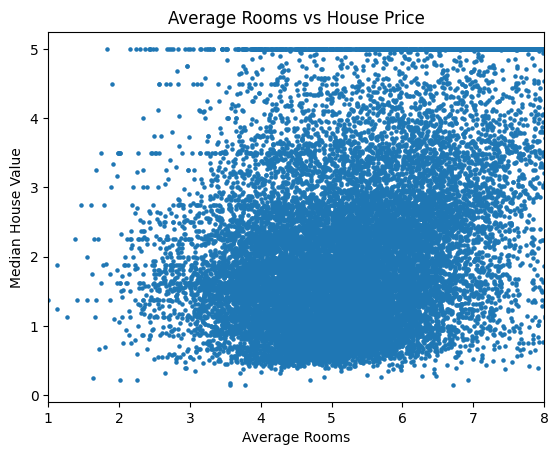

In [9]:
#Visualizing the data
import matplotlib.pyplot as plt
plt.scatter(X,Y,s=5)

plt.xlabel("Average Rooms")
plt.xlim(1,8)

plt.ylabel("Median House Value")

plt.title("Average Rooms vs House Price")

plt.show()

In [10]:
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.linear_model import SGDRegressor, LinearRegression

model=LinearRegression()
model.fit(X_train,y_train)

print(model.coef_)
print(model.intercept_)

[0.07675559]
1.6547622685968417


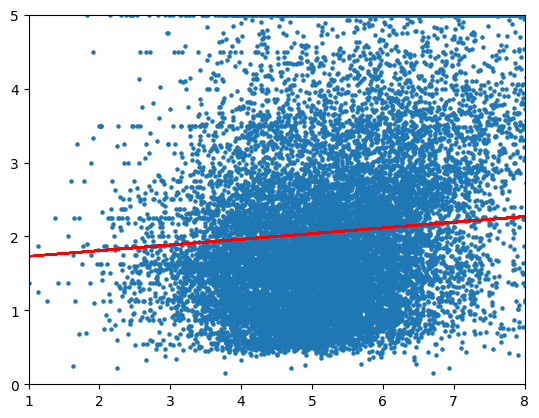

In [16]:
#sample regression line
pred=model.predict(X_train)
plt.scatter(X_train,y_train,s=5)
plt.xlim(1,8)
plt.ylim(0,5)
plt.plot(X_train,pred,color="red")

plt.show()

In [15]:
y_pred=model.predict(X_test)

mse=mean_squared_error(y_test,y_pred)
print(mse)

r2=r2_score(y_test,y_pred)
print(r2)

1.2923314440807299
0.013795337532284901


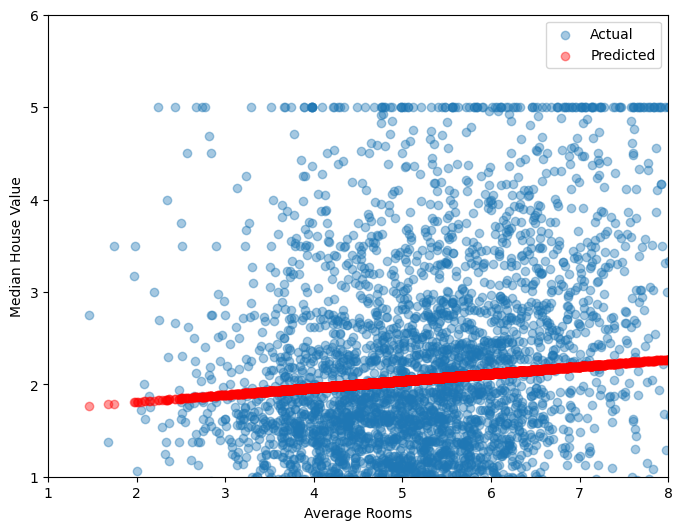

In [20]:
plt.figure(figsize=(8,6))

plt.scatter(X_test,
            y_test,
            alpha=0.4,
            label="Actual")

plt.scatter(X_test,
            y_pred,
            color="red",
            alpha=0.4,
            label="Predicted")


plt.xlabel("Average Rooms")
plt.xlim(1,8)

plt.ylabel("Median House Value")
plt.ylim(1,6)

plt.legend()

plt.show()